In [1]:
import warnings
warnings.filterwarnings(action='ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
import seaborn as sns
import sklearn
from sklearn import datasets
sklearn.set_config(display='text')
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler, RobustScaler, MinMaxScaler, Normalizer
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, silhouette_score
from sklearn.ensemble import RandomForestClassifier

# 커널 주성분 분석(Kernel Principal Component Analysis, KPCA)

주성분 분석은 데이터 행렬 X의 공분산 행렬을 고유값으로 분해한 후 고유 벡터를 새로운 좌표 축에 할당하는 방법이었다.  
기존 데이터 포인트는 새로운 좌표 축을 기준을 좌표를 할당받았다. 이때 사용하는 새로운 좌표 축에 해당하는 고유 벡터를 주성분이라고 불렀으며, 기존 데이터 포인트를 주성분에 직교 정사영하는 방법을 사용했었다. 이에 반해 커널 주성분 분석은 주성분 분석을 일반화한 방법으로 비선형적으로 수행하는 방법이다.

기존 데이터 행렬X를 기존 데이터 행렬보다 `큰 공간으로 매핑`한 후 새로운 공간으로 이동한 데이터에 대해서 `다시 주성분 분석`을 실시한다. 그리고 데이터를 다시 원래 공간으로 매핑시키면 곡선 형태를 띈 주성분 축을 확인할 수 있다.

# 차원을 축소하기 전과 차원을 축소한 후 정확도를 비교한다.

## 와인 데이터를 커널 주성분 분석 알고리즘에 사용할 데이터를 준비한다.

In [2]:
raw_data = datasets.load_wine()

xData = raw_data.data
yData = raw_data.target

x_train, x_test, y_train, y_test = train_test_split(xData, yData, random_state=1)

scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

## 커널 주성분 분석 모델을 만들고 학습 시킨다.

커널 주성분 분석을 알고리즘을 사용하기 위해 KernelPCA를 import 한다.

In [3]:
from sklearn.decomposition import KernelPCA

n_components에 축소하려는 차원 크기와 kernel에 사용할 커널를 지정해서 커널 주성분 분석 모델을 만들고 학습한 후 적용시킨다.  
kernel의 기본값은 linear이고 rbf, poly, sigmoid, cosine, precompute를 지정할 수 있다.

In [7]:
model = KernelPCA(n_components=2, kernel='linear')
# model.fit(x_train)
# x_train_kpca = model.transform(x_train)
x_train_kpca = model.fit_transform(x_train)
x_test_kpca = model.transform(x_test)
print(x_train.shape, x_train_kpca.shape, x_test.shape, x_test_kpca.shape)

(133, 13) (133, 2) (45, 13) (45, 2)


## 고유값, 고유 벡터를 확인한다.

eigenvalues_ 속성으로 차원 축소에 사용된 고유값을 얻어올 수 있다.

In [8]:
print(model.eigenvalues_)

[615.93183073 335.53461284]


eigenvectors_ 속성으로 차원 축소에 사용된 고유 벡터를 얻어올 수 있다.

In [9]:
print(model.eigenvectors_)

[[-0.08992871 -0.00811256]
 [-0.05497805  0.02307161]
 [-0.07728561 -0.10998612]
 [-0.14260921 -0.15713815]
 [-0.12822643 -0.11027867]
 [ 0.05592673  0.07308611]
 [ 0.09812815 -0.10943304]
 [ 0.10979478 -0.07248396]
 [-0.08976111 -0.04889812]
 [ 0.04349532  0.11784543]
 [-0.10306627 -0.03501269]
 [-0.09157717 -0.05064941]
 [-0.04933791  0.08748824]
 [ 0.11747176 -0.01204031]
 [-0.09991292  0.0957447 ]
 [ 0.01010678  0.04637582]
 [-0.07766339 -0.10276567]
 [ 0.11614199 -0.0720266 ]
 [ 0.00989174  0.14669507]
 [ 0.12157994  0.0236528 ]
 [-0.14152814 -0.07848275]
 [ 0.00395407  0.1189435 ]
 [-0.04814944 -0.10339427]
 [-0.04111756  0.12599102]
 [-0.06019432 -0.048595  ]
 [ 0.14278483 -0.03116041]
 [ 0.09713137 -0.13039342]
 [ 0.08728639 -0.10534613]
 [ 0.10813284 -0.14163546]
 [ 0.08755698  0.07800966]
 [ 0.02354319  0.13113314]
 [-0.0493864  -0.01530116]
 [ 0.13308197 -0.10358656]
 [-0.10430377 -0.06593992]
 [ 0.05604721  0.04538122]
 [ 0.09959929 -0.03236242]
 [-0.10142702 -0.07914393]
 

## 커널 주성분 분석을 통해 차원 축소된 데이터 시각화

In [10]:
df = pd.DataFrame(x_train_kpca, columns=['x', 'y'])
df['label'] = y_train
df

,x,y,label
0,-2.231848,-0.148603,0
1,-1.364444,0.422617,1
2,-1.918072,-2.014682,0
3,-3.539272,-2.878394,0
4,-3.182320,-2.020041,0
...,...,...,...
128,1.995535,-0.227742,2
129,3.785334,-0.303041,2
130,0.530538,1.093638,1
131,2.625701,-0.163952,2


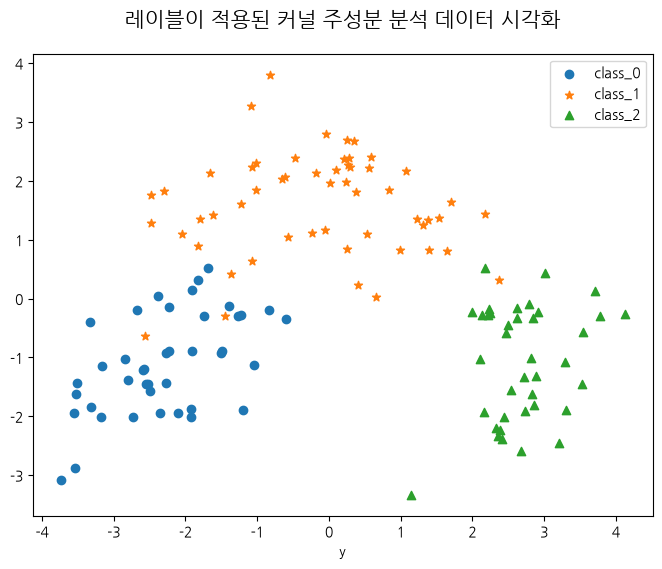

In [11]:
plt.figure(figsize=[8, 6])
markers = ['o', '*', '^', 'v', 's', 'x']

for i in range(len(raw_data.target_names)):
    df_index = df[df.label == i]
    label = raw_data.target_names[i]
    plt.scatter(x=df_index.x, y=df_index.y, label=label, marker=markers[i])

plt.title('레이블이 적용된 커널 주성분 분석 데이터 시각화', pad=20, fontsize=15)
plt.xlabel('x')
plt.xlabel('y')
plt.legend()
plt.show()

## 커널 주성분 분석 적용 전, 후 데이터로 랜덤 포레스트 모델로 학습시키고 예측 후 평가한다.

커널 주성분 분석 전 데이터 학습 및 예측, 평가

In [12]:
model = RandomForestClassifier(random_state=0, max_depth=2).fit(x_train, y_train)
predict = model.predict(x_test)
print(predict)

[2 1 0 1 0 2 1 0 2 1 0 0 1 0 1 1 2 0 1 0 0 1 2 0 0 2 0 0 0 2 1 2 2 0 1 1 1
 1 1 0 0 1 2 0 0]


In [13]:
classification = classification_report(y_test, predict, target_names=raw_data.target_names)
print(classification)

              precision    recall  f1-score   support

     class_0       0.95      1.00      0.97        18
     class_1       1.00      0.94      0.97        17
     class_2       1.00      1.00      1.00        10

    accuracy                           0.98        45
   macro avg       0.98      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45



커널 주성분 분석 후 데이터 학습 및 예측, 평가

In [15]:
model_kpca = RandomForestClassifier(random_state=0, max_depth=2).fit(x_train_kpca, y_train)
predict_kpca = model_kpca.predict(x_test_kpca)
print(predict_kpca)

[2 1 0 1 0 2 1 0 2 1 0 0 1 0 1 1 2 0 1 0 0 1 0 0 0 2 0 0 0 2 1 2 2 0 1 1 1
 1 1 0 0 1 2 0 0]


In [16]:
classification = classification_report(y_test, predict_kpca, target_names=raw_data.target_names)
print(classification)

              precision    recall  f1-score   support

     class_0       0.90      1.00      0.95        18
     class_1       1.00      0.94      0.97        17
     class_2       1.00      0.90      0.95        10

    accuracy                           0.96        45
   macro avg       0.97      0.95      0.95        45
weighted avg       0.96      0.96      0.96        45

